# Figure 5 panels E-H, from the RDS files

Panels **E** and **G** (allele-stratified coverage + factor tracks + isoform
models) and **F** and **H** (factor loadings by genotype), rebuilt from the
RDS on disk. Nothing here reads or writes a pickle and nothing is saved — swap
the gene, variant, tissue, factorisation **or RDS tree** and rerun.

The functions live in `Figure5_examples.py`; the drawing code is the same as
the assembled figure's, lifted out of the millimetre page layout.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

FIG5_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure5'
if FIG5_DIR not in sys.path:
    sys.path.append(FIG5_DIR)

import Figure5_examples as EX

print('coverage RDS :', EX.COV_RDS)
print('boxplot  RDS :', EX.BOX_RDS)
print('factors  RDS :', EX.GAO_RDS_ALL)
print('isoform bed  :', EX.ISOFORM_BED)

coverage RDS : /project2/yangili1/cfbuenabadn/torino_paper/code/UofC_plots/coverage_matrices_rds
boxplot  RDS : /project2/yangili1/cfbuenabadn/torino_paper/code/ad_genetics/UofC_plots/boxplot_rds
factors  RDS : /project2/mstephens/cfbuenabadn/gtex-stm/code/ebpmf_models/gao_models/RDS_all
isoform bed  : /project2/mstephens/cfbuenabadn/gtex-stm/code/results/gao/isoforms/isoforms.bed.gz


## What is on disk

`list_available()` enumerates the RDS files, `gene_isoforms()` shows a gene's
isoform models and which factor each carries — together they tell you what a
new panel can be made of.

In [3]:
# What can be plotted. Every (gene, variant, tissue) below has both a coverage
# and a boxplot RDS, so any row works for a locus panel and its boxplot.
available = EX.list_available(kind='coverage')
print(f'{len(available)} coverage RDS over {available.gene.nunique()} genes, '
      f'{available.tissue.nunique()} tissues')
print(available.groupby(['gene', 'tissue']).size().unstack(fill_value=0))

# The isoform models of a gene, and which factor each one carries — this is how
# to choose `transcripts` and `factor_list` for a gene you have not plotted yet.
EX.gene_isoforms('ENSG00000103550')

150 coverage RDS over 3 genes, 3 tissues
tissue           AC  DLPFC  PCC
gene                           
ENSG00000055950   6      6    6
ENSG00000103550  17     17   17
ENSG00000122873  27     27   27


,transcript_id,factors,strand,n_exons,start,end
0,ENSG00000103550.isoform_1,factor_1,-,6,19702183,19718215
1,ENSG00000103550.isoform_2,factor_2,-,4,19706479,19718215
2,ENSG00000103550.isoform_3,factor_3:factor_5,-,5,19703254,19718218
3,ENSG00000103550.isoform_4,factor_4,-,2,19701901,19715035


## Panel E — *KNOP1* locus in PCC

Three calls: `load_coverage` (the RDS), `load_factors` (the snmf model), and
`locus_spec` for everything that is presentation rather than data.

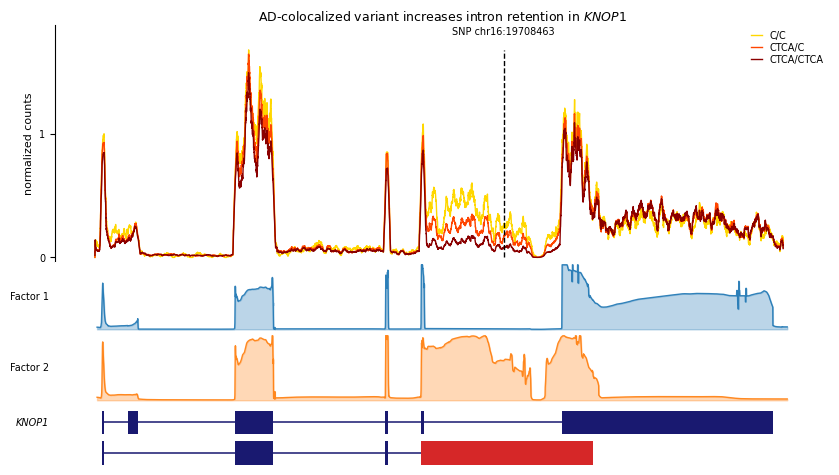

In [4]:
# Panel E — KNOP1 in PCC, built the long way so every piece is visible.
KNOP1 = 'ENSG00000103550'
KNOP1_SNP = 'chr16:19708463:CTCA:C'

knop1_cov = EX.load_coverage(KNOP1, KNOP1_SNP, 'PCC')
knop1_fac = EX.load_factors(KNOP1, k=5)

knop1_spec = EX.locus_spec(
    KNOP1, name='KNOP1',
    # only the isoforms carrying the two factors drawn above them
    transcripts=[f'{KNOP1}.isoform_1', f'{KNOP1}.isoform_2'],
    # the AD event: the retained intron, drawn in red
    highlight={f'{KNOP1}.isoform_2': (19706479, 19710586)},
    factor_list=['factor1', 'factor2'],
    factor_labels=['Factor 1', 'Factor 2'],
    colors=['tab:blue', 'tab:orange'])

EX.plot_locus(knop1_cov, knop1_fac, knop1_spec,
              title='AD-colocalized variant increases intron retention in '
                    '$\\it{KNOP1}$',
              snp_label=f'SNP {KNOP1_SNP.rsplit(":", 2)[0]}')
plt.show()

## Panel F — *KNOP1* factor 2 by genotype

factor columns: ['ENSG00000103550.factor_2', 'ENSG00000103550.factor_1', 'ENSG00000103550.factor_3', 'ENSG00000103550.factor_4', 'ENSG00000103550.factor_5']


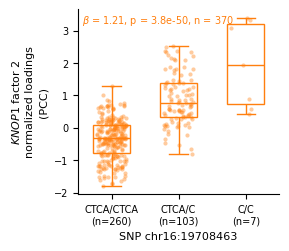

In [5]:
# Panel F — the same variant's loadings by genotype. `order` fixes the allele
# dosage direction; the colour matches factor 2's track in panel E.
knop1_box = EX.load_boxplot(KNOP1, KNOP1_SNP, 'PCC')
print('factor columns:', EX.factor_columns(knop1_box))

# regression=True fits factor ~ allele dosage and writes beta and p into the
# corner. Dosage counts steps along `order`, so here it is per C allele.
EX.plot_genotype_boxplot(
    knop1_box, f'{KNOP1}.factor_2', order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
    color='tab:orange', regression=True,
    ylabel='$\\it{KNOP1}$ factor 2\nnormalized loadings\n(PCC)',
    xlabel='SNP chr16:19708463')
plt.show()

## Panel G — *CISD1* locus in AC

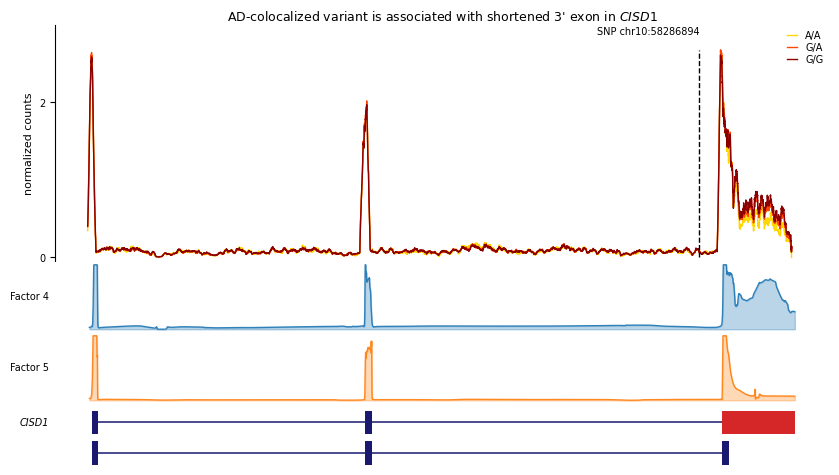

In [6]:
# Panel G — CISD1 in AC. Same three calls, different arguments.
CISD1 = 'ENSG00000122873'
CISD1_SNP = 'chr10:58286894:G:A'

cisd1_cov = EX.load_coverage(CISD1, CISD1_SNP, 'AC')
cisd1_fac = EX.load_factors(CISD1, k=5)

cisd1_spec = EX.locus_spec(
    CISD1, name='CISD1',
    transcripts=[f'{CISD1}.isoform_2', f'{CISD1}.isoform_4'],
    # the long 3' exon the risk allele shortens
    highlight={f'{CISD1}.isoform_2': (58287561, 58289682)},
    factor_list=['factor4', 'factor5'],
    factor_labels=['Factor 4', 'Factor 5'],
    colors=['tab:blue', 'tab:orange'])

EX.plot_locus(cisd1_cov, cisd1_fac, cisd1_spec,
              title="AD-colocalized variant is associated with shortened 3' "
                    "exon in $\\it{CISD1}$",
              snp_label='SNP chr10:58286894', snp_ha='right')
plt.show()

## Panel H — *CISD1* factor 4 by genotype

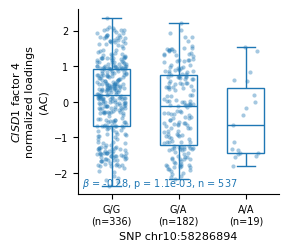

In [7]:
cisd1_box = EX.load_boxplot(CISD1, CISD1_SNP, 'AC')

EX.plot_genotype_boxplot(
    cisd1_box, f'{CISD1}.factor_4', order=['G/G', 'G/A', 'A/A'],
    color='tab:blue', regression=True, reg_loc='lower left',
    ylabel='$\\it{CISD1}$ factor 4\nnormalized loadings\n(AC)',
    xlabel='SNP chr10:58286894')
plt.show()

## Swapping in a different gene, variant or tissue

The point of the module: the same functions, different arguments. With no
`spec`, every isoform is drawn under every factor — the right first look at a
locus you have not seen before.

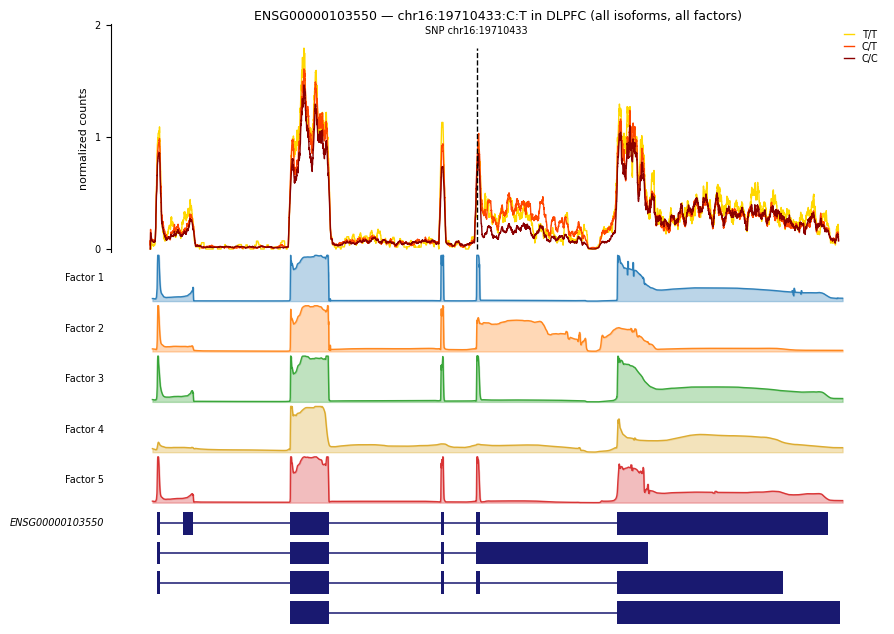

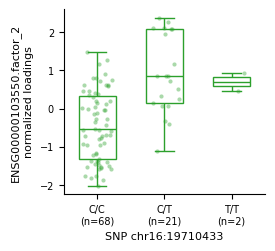

In [2]:
# A different gene-variant-tissue, with nothing else changed.
#
# With no `spec` at all, plot_locus draws every isoform of the gene under every
# factor of the model — the right starting point for a locus you have not
# looked at before. Narrow it with locus_spec() once you know which isoform and
# which factor carry the event.
GENE, SNP, TISSUE = 'ENSG00000103550', 'chr16:19710433:C:T', 'DLPFC'

cov = EX.load_coverage(GENE, SNP, TISSUE)
fac = EX.load_factors(GENE, k=5)

EX.plot_locus(cov, fac, title=f'{GENE} — {SNP} in {TISSUE} (all isoforms, all factors)',
              snp_label=f'SNP {SNP.rsplit(":", 2)[0]}',
              figsize=(9, 6), track_h=0.22)
plt.show()

box = EX.load_boxplot(GENE, SNP, TISSUE)
EX.plot_genotype_boxplot(box, f'{GENE}.factor_2', order=['C/C', 'C/T', 'T/T'],
                         color='tab:green', xlabel=f'SNP {SNP.rsplit(":", 2)[0]}')
plt.show()

## Pointing at an RDS file directly

/project2/yangili1/cfbuenabadn/torino_paper/code/UofC_plots/coverage_matrices_rds/ENSG00000122873.chr10:58286894:G:A.PCC.coverage_matrices.rds -> True


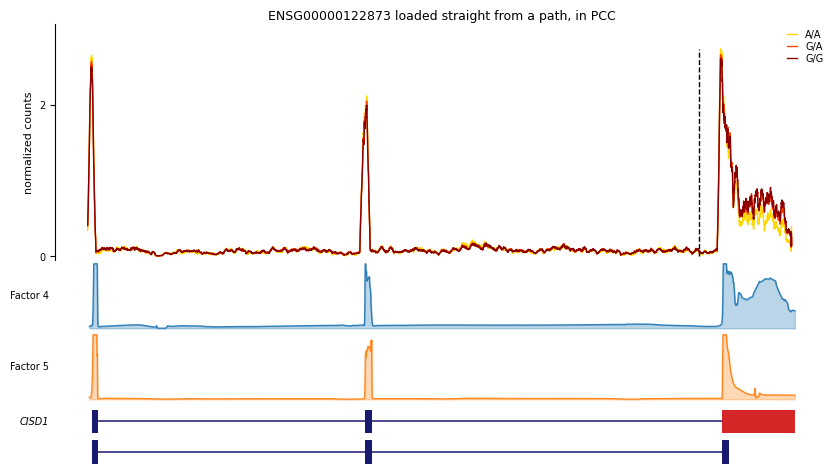

In [9]:
# Any coverage_matrices RDS can be given directly with `rds_path`, for a file
# that does not follow the {gene}.{variant}.{tissue} naming. `gene` is still
# needed, to pick the isoform models and the strand.
path = EX.coverage_rds_path(CISD1, CISD1_SNP, 'PCC')
print(path, '->', os.path.exists(path))

cov_direct = EX.load_coverage(CISD1, rds_path=path)
EX.plot_locus(cov_direct, cisd1_fac, cisd1_spec,
              title=f'{CISD1} loaded straight from a path, in PCC')
plt.show()

## Shortcut for the four published panels

`plot_panel()` carries the stored titles, colours and genotype orders. Any
keyword overrides one of them; it is the same code path, not a second one.

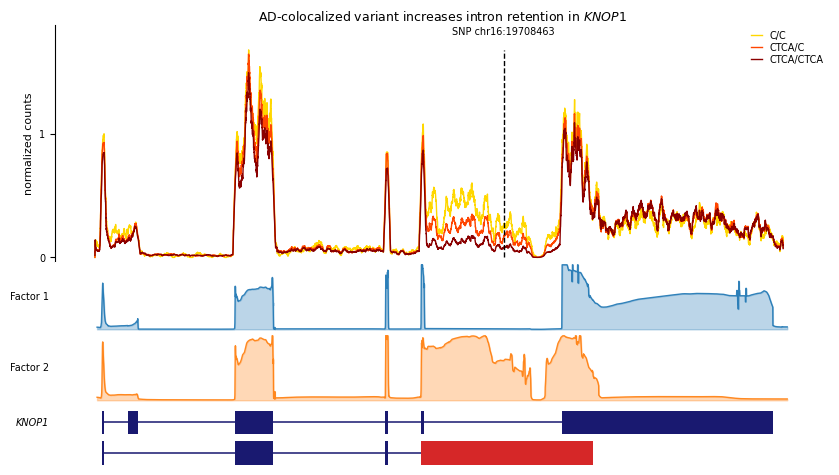

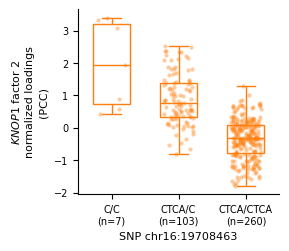

In [10]:
# The four published panels, with their stored titles, colours and orders.
# Any keyword overrides one setting, so this is the same code path as above.
EX.plot_panel('E')
plt.show()

EX.plot_panel('F', order=['C/C', 'CTCA/C', 'CTCA/CTCA'])   # axis flipped
plt.show()

## Switching the RDS tree

`root=` takes a key of `EX.RDS_ROOTS` or any path, and `group=` reaches into the
extra `AD/` `nonAD/` level the `*_by_AD` trees carry. Nothing else about the
call changes, so the same four panel functions cover every tree.

In [11]:
# Switching the whole RDS tree, not just the gene.
#
# `root=` takes a key of EX.RDS_ROOTS or any path; `group=` reaches into the
# extra AD/ nonAD level the *_by_AD trees carry. Nothing else about the call
# changes.
for k, v in EX.RDS_ROOTS.items():
    print(f'  {k:24s} {v}')

# Which trees actually hold this gene-variant-tissue.
print()
print(EX.compare_roots(KNOP1, KNOP1_SNP, 'PCC', kind='boxplot')[
    ['root', 'group', 'exists']].to_string(index=False))

  coverage                 /project2/yangili1/cfbuenabadn/torino_paper/code/UofC_plots/coverage_matrices_rds
  coverage_ad_genetics     /project2/yangili1/cfbuenabadn/torino_paper/code/ad_genetics/UofC_plots/coverage_matrices_rds
  k3_coverage              /project2/yangili1/cfbuenabadn/torino_paper/code/k3_figure_202609-v2/coverage_matrices_rds
  k3_coverage_by_AD        /project2/yangili1/cfbuenabadn/torino_paper/code/k3_figure_202609-v2/coverage_matrices_rds_by_AD
  boxplot                  /project2/yangili1/cfbuenabadn/torino_paper/code/ad_genetics/UofC_plots/boxplot_rds
  k3_unnormalized          /project2/yangili1/cfbuenabadn/torino_paper/code/k3_figure_202609-v2/boxplot_rds_unnormalized
  k3_unnormalized_by_AD    /project2/yangili1/cfbuenabadn/torino_paper/code/k3_figure_202609-v2/boxplot_rds_unnormalized_by_AD
  k3_qqnorm                /project2/yangili1/cfbuenabadn/torino_paper/code/k3_figure_202609-v2/boxplot_rds_qqnorm
  k3_qqnorm_by_AD          /project2/yangili1/cfbuenab

## Comparing normalisations

Panel F under `boxplot_rds_unnormalized` and `boxplot_rds_qqnorm`.

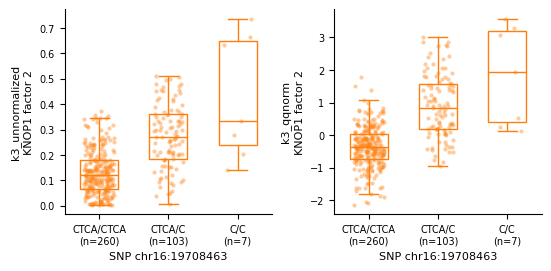

In [12]:
# The same panel F under the two K=3 normalisations.
#
# These trees are the K=3 rerun: their boxplots carry factor_1..factor_3 plus an
# `AD` column, which factor_columns() knows to leave out.
fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.6), constrained_layout=True)
for ax, root in zip(axes, ['k3_unnormalized', 'k3_qqnorm']):
    df = EX.load_boxplot(KNOP1, KNOP1_SNP, 'PCC', root=root)
    EX.plot_genotype_boxplot(df, f'{KNOP1}.factor_2',
                             order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                             color='tab:orange', ax=ax,
                             ylabel=f'{root}\nKNOP1 factor 2',
                             xlabel='SNP chr16:19708463')
plt.show()

## AD vs non-AD

The `*_by_AD` trees split the same samples; `group=` picks the half.

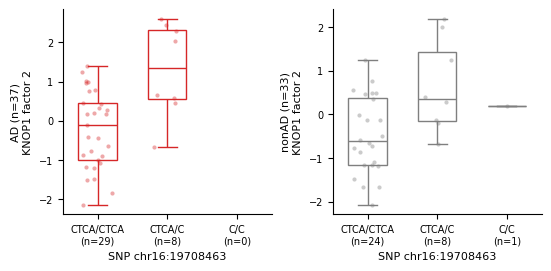

In [13]:
# AD vs non-AD, for the same variant. Same call, one extra argument.
fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.6), constrained_layout=True)
for ax, grp in zip(axes, ['AD', 'nonAD']):
    df = EX.load_boxplot(KNOP1, KNOP1_SNP, 'DLPFC', root='k3_qqnorm_by_AD', group=grp)
    EX.plot_genotype_boxplot(df, f'{KNOP1}.factor_2',
                             order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                             color='tab:red' if grp == 'AD' else 'tab:gray', ax=ax,
                             ylabel=f'{grp} (n={len(df)})\nKNOP1 factor 2',
                             xlabel='SNP chr16:19708463')
plt.show()

## K=3 coverage

`coverage_matrices_rds` and `coverage_matrices_rds_by_AD`, with the
factorisation (`k=3`) and the isoform bed (`H.K3_ISOFORMS`) switched to match.

            transcript_id           factors strand  n_exons    start      end
ENSG00000103550.isoform_1 factor_1:factor_3      -        5 19703353 19718218
ENSG00000103550.isoform_2          factor_2      -        4 19706482 19718215


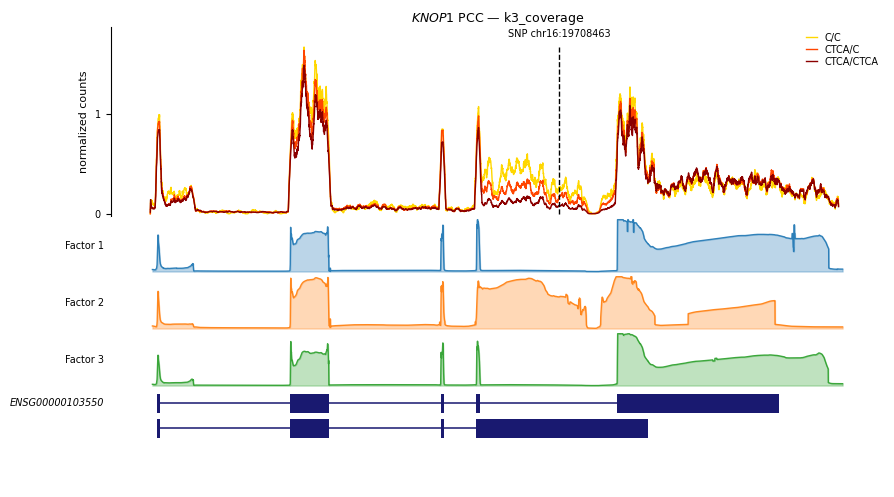

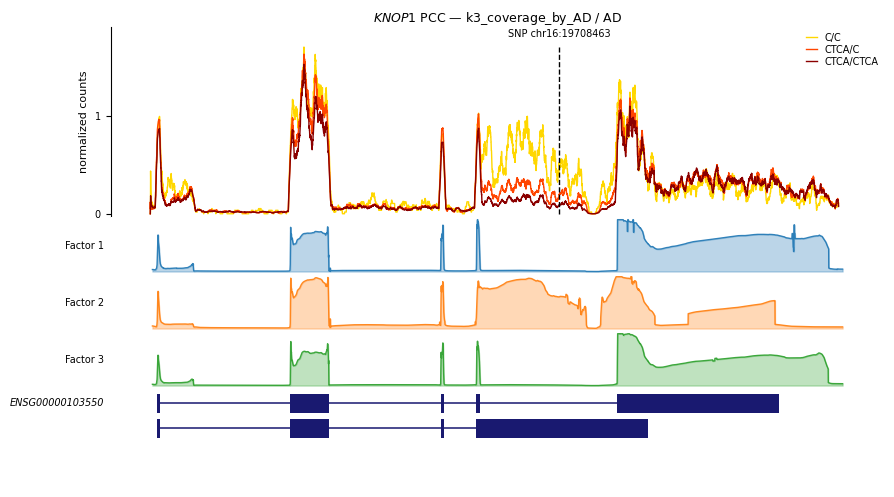

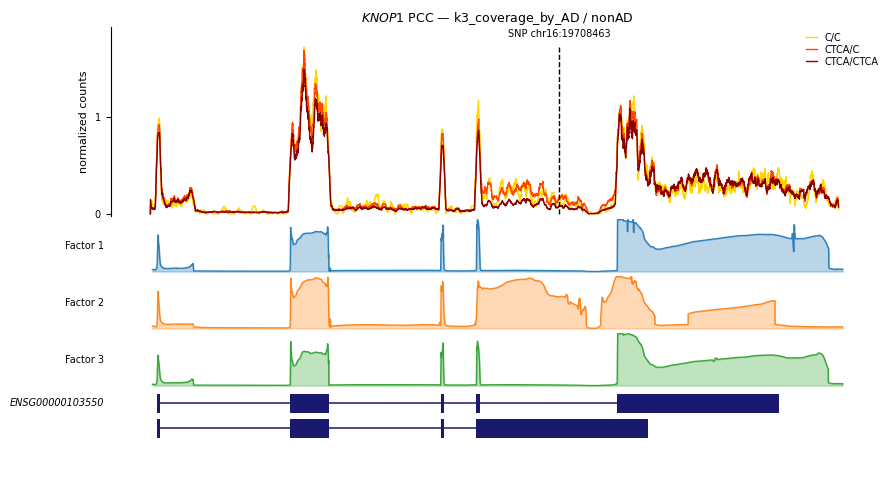

In [14]:
# The K=3 coverage trees, with the factorisation and the isoform bed switched to
# match: k=3 reads snmf_3, and H.K3_ISOFORMS is the gao_k3 bed. Mixing a K=3
# coverage with the K=5 bed gives the same xlim but shifts the exon models.
import Figure5_helpers as H

knop1_fac_k3 = EX.load_factors(KNOP1, k=3, iso_path=H.K3_ISOFORMS)
print(EX.gene_isoforms(KNOP1, iso_path=H.K3_ISOFORMS).to_string(index=False))

for root, grp in [('k3_coverage', None),
                  ('k3_coverage_by_AD', 'AD'),
                  ('k3_coverage_by_AD', 'nonAD')]:
    cov = EX.load_coverage(KNOP1, KNOP1_SNP, 'PCC', root=root, group=grp,
                           iso_path=H.K3_ISOFORMS)
    EX.plot_locus(cov, knop1_fac_k3,
                  title=f'$\\it{{KNOP1}}$ PCC — {root}' + (f' / {grp}' if grp else ''),
                  snp_label='SNP chr16:19708463', figsize=(9, 4.6))
    plt.show()

## By-AD boxplots with the tissues pooled

Each AD / non-AD box holds AC + PCC + DLPFC together, with the tissue kept
visible through the marker: **AC `+`, PCC `x`, DLPFC `^`**.

`POOLED_ROOT` is the single knob — every pooled plot below is drawn from the
frame loaded with it, so changing it here changes the figures.

tissue   AC  DLPFC  PCC
group                  
AD      200     37  127
nonAD   181     33  133

tree: k3_qqnorm_by_AD  range: -2.171 .. 3.576


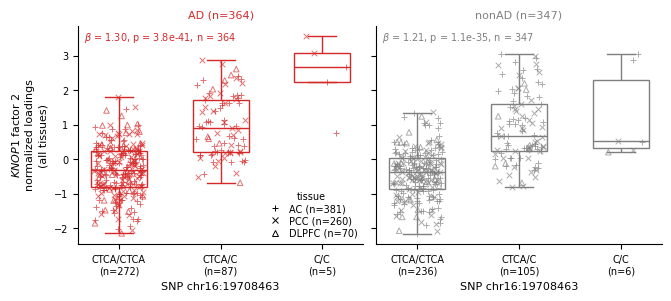

In [ ]:
# SAVE THIS FIGURE

# By-AD boxplots with the three tissues pooled into each box.
#
# The boxes summarise AC + PCC + DLPFC together; the marker keeps each point
# attributable (AC '+', PCC 'x', DLPFC '^').
#
# POOLED_ROOT is the one place to change: every pooled plot below loads from it,
# and plot_by_ad_boxplot takes the frame, so swapping it here actually changes
# what is drawn. 'k3_qqnorm_by_AD' is quantile-normalised within each tissue, so
# its values are comparable across tissues; 'k3_unnormalized_by_AD' is not, and
# pooling it also mixes the three tissues' scales.
POOLED_ROOT = 'k3_qqnorm_by_AD'

knop1_pooled = EX.load_by_ad_tissues(KNOP1, KNOP1_SNP, root=POOLED_ROOT)
print(knop1_pooled.groupby(['group', 'tissue']).size().unstack(fill_value=0))
print(f"\ntree: {knop1_pooled.attrs['root']}  "
      f"range: {knop1_pooled[f'{KNOP1}.factor_2'].min():.3f} .. "
      f"{knop1_pooled[f'{KNOP1}.factor_2'].max():.3f}")

# KNOP1 — factor 2 is the retained-intron isoform, and it rises with the C allele.
# Drawn from `knop1_pooled`, so it follows POOLED_ROOT. The y-axis wording comes
# from the frame's tree, so it can never claim "normalized" for a raw loading.
# The fit runs separately within AD and non-AD. reg_covariates=['tissue']
# adjusts for the pooling, so a tissue difference in mean loading cannot show
# up as a genotype effect.
EX.plot_by_ad_boxplot(knop1_pooled, f'{KNOP1}.factor_2',
                      order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                      regression=True, reg_covariates=['tissue'],
                      ylabel=f'$\\it{{KNOP1}}$ factor 2\n'
                             f'{EX.loading_label(POOLED_ROOT)}\n(all tissues)',
                      xlabel='SNP chr16:19708463')
plt.show()

tissue   AC  DLPFC  PCC
group                  
AD      200     37  127
nonAD   181     33  133

tree: k3_qqnorm_by_AD  range: -2.171 .. 3.576


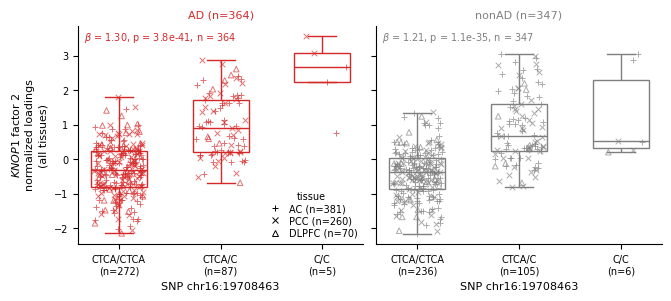

In [81]:
# By-AD boxplots with the three tissues pooled into each box.
#
# The boxes summarise AC + PCC + DLPFC together; the marker keeps each point
# attributable (AC '+', PCC 'x', DLPFC '^').
#
# POOLED_ROOT is the one place to change: every pooled plot below loads from it,
# and plot_by_ad_boxplot takes the frame, so swapping it here actually changes
# what is drawn. 'k3_qqnorm_by_AD' is quantile-normalised within each tissue, so
# its values are comparable across tissues; 'k3_unnormalized_by_AD' is not, and
# pooling it also mixes the three tissues' scales.
POOLED_ROOT = 'k3_qqnorm_by_AD'

knop1_pooled = EX.load_by_ad_tissues(KNOP1, KNOP1_SNP, root=POOLED_ROOT)
print(knop1_pooled.groupby(['group', 'tissue']).size().unstack(fill_value=0))
print(f"\ntree: {knop1_pooled.attrs['root']}  "
      f"range: {knop1_pooled[f'{KNOP1}.factor_2'].min():.3f} .. "
      f"{knop1_pooled[f'{KNOP1}.factor_2'].max():.3f}")

# KNOP1 — factor 2 is the retained-intron isoform, and it rises with the C allele.
# Drawn from `knop1_pooled`, so it follows POOLED_ROOT. The y-axis wording comes
# from the frame's tree, so it can never claim "normalized" for a raw loading.
# The fit runs separately within AD and non-AD. reg_covariates=['tissue']
# adjusts for the pooling, so a tissue difference in mean loading cannot show
# up as a genotype effect.
EX.plot_by_ad_boxplot(knop1_pooled, f'{KNOP1}.factor_2',
                      order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                      regression=True, reg_covariates=['tissue'],
                      ylabel=f'$\\it{{KNOP1}}$ factor 2\n'
                             f'{EX.loading_label(POOLED_ROOT)}\n(all tissues)',
                      xlabel='SNP chr16:19708463')
plt.show()

### *CISD1*

The K=3 factor numbering is not the K=5 one panel H used — check which factor
carries the event before picking one.

            transcript_id           factors strand  n_exons    start      end
ENSG00000122873.isoform_1          factor_1      +        3 58269126 58288521
ENSG00000122873.isoform_2 factor_2:factor_3      +        3 58269126 58289463
          ENSG00000122873.factor_1  ENSG00000122873.factor_2  \
genotype                                                       
G/G                         -0.094                     0.044   
G/A                          0.093                    -0.077   
A/A                          0.631                    -0.659   

          ENSG00000122873.factor_3  
genotype                            
G/G                          0.063  
G/A                         -0.026  
A/A                          0.039  


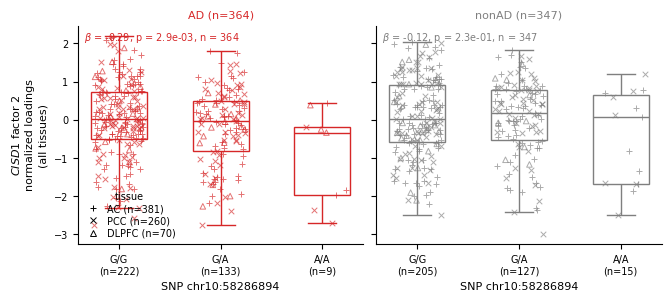

In [82]:
# SAVE THIS FIGURE
# CISD1 — note the factor numbering is not the K=5 one panel H used. In the K=3
# model isoform_1 is the short 3' form (factor_1) and isoform_2 the long one
# (factor_2 / factor_3), so the A allele raises factor_1 and lowers factor_2:
print(EX.gene_isoforms(CISD1, iso_path=H.K3_ISOFORMS).to_string(index=False))

cisd1_pooled = EX.load_by_ad_tissues(CISD1, CISD1_SNP, root=POOLED_ROOT)
print(cisd1_pooled.groupby('genotype')[EX.factor_columns(cisd1_pooled)]
      .mean().reindex(['G/G', 'G/A', 'A/A']).round(3))

EX.plot_by_ad_boxplot(cisd1_pooled, f'{CISD1}.factor_2',
                      order=['G/G', 'G/A', 'A/A'], legend_loc='lower left',
                      regression=True, reg_covariates=['tissue'],
                      ylabel=f'$\\it{{CISD1}}$ factor 2\n'
                             f'{EX.loading_label(POOLED_ROOT)}\n(all tissues)',
                      xlabel='SNP chr10:58286894')
plt.show()

In [ ]:
### THIS CISD1 FIGURE TO REPLICATE
# CISD1 — note the factor numbering is not the K=5 one panel H used. In the K=3
# model isoform_1 is the short 3' form (factor_1) and isoform_2 the long one
# (factor_2 / factor_3), so the A allele raises factor_1 and lowers factor_2:
POOLED_ROOT = 'k3_qqnorm_by_AD'

print(EX.gene_isoforms(CISD1, iso_path=H.K3_ISOFORMS).to_string(index=False))

cisd1_pooled = EX.load_by_ad_tissues(CISD1, CISD1_SNP, root=POOLED_ROOT)
print(cisd1_pooled.groupby('genotype')[EX.factor_columns(cisd1_pooled)]
      .mean().reindex(['G/G', 'G/A', 'A/A']).round(3))

# stats printed, not drawn -- the annotation's headroom was flattening the boxes
_ax = EX.plot_by_ad_boxplot(cisd1_pooled, f'{CISD1}.factor_2',
                            order=['G/G', 'G/A', 'A/A'], legend_loc='lower left',
                            regression=True, reg_covariates=['tissue'],
                            ylabel=f'$\\it{{CISD1}}$ factor 2\n'
                                   f'{EX.loading_label(POOLED_ROOT)}\n(all tissues)',
                            xlabel='SNP chr10:58286894')
print()
print(EX.report_regressions(_ax).to_string(index=False))
plt.show()


### Taking it apart, and checking the root reaches the plot

`load_by_ad_tissues` returns the pooled frame and `plot_by_ad_boxplot` draws it,
so tissues, markers and factor are all free. The last figure draws both trees
side by side: unnormalized loadings are positive and on the raw scale, qqnorm
ones centred near zero.

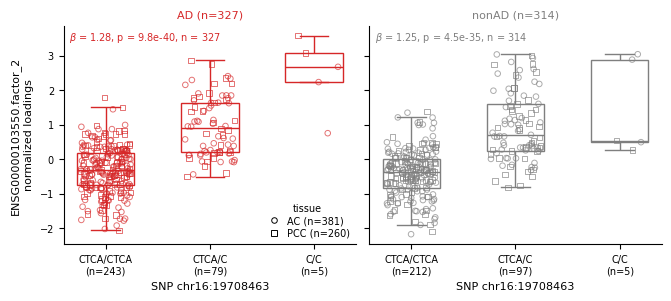

  note: k3_unnormalized_by_AD is not quantile-normalised, so pooling ['AC', 'DLPFC', 'PCC'] mixes their scales


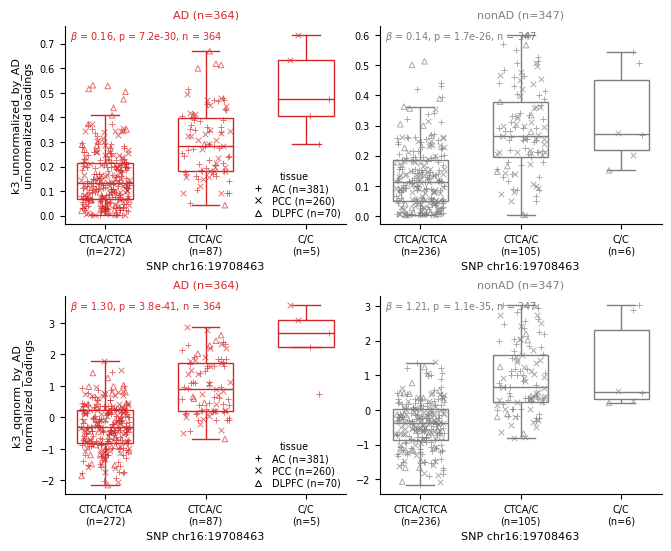

In [21]:
# Taking it apart: any subset of tissues, any markers, any factor.
# `load_by_ad_tissues` gives the pooled frame and `plot_by_ad_boxplot` draws it,
# so anything pandas can do to the frame fits in between.
two = EX.load_by_ad_tissues(KNOP1, KNOP1_SNP, tissues=('AC', 'PCC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{KNOP1}.factor_2',
                      order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                      regression=True, #reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's'},
                      xlabel='SNP chr16:19708463')   # y label follows the tree
plt.show()

# The same panel under both trees, side by side — the check that a root swap is
# really reaching the plot. Unnormalized loadings are all positive and on the
# raw scale; qqnorm ones are centred near zero.
fig, axes = plt.subplots(2, 2, figsize=(6.6, 5.4), constrained_layout=True)
for row, root in zip(axes, ['k3_unnormalized_by_AD', 'k3_qqnorm_by_AD']):
    d = EX.load_by_ad_tissues(KNOP1, KNOP1_SNP, root=root)
    EX.plot_by_ad_boxplot(d, f'{KNOP1}.factor_2', axes=row,
                          order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                          regression=True, reg_covariates=['tissue'],
                          ylabel=f'{root}\n{EX.loading_label(root)}',
                          xlabel='SNP chr16:19708463')
plt.show()

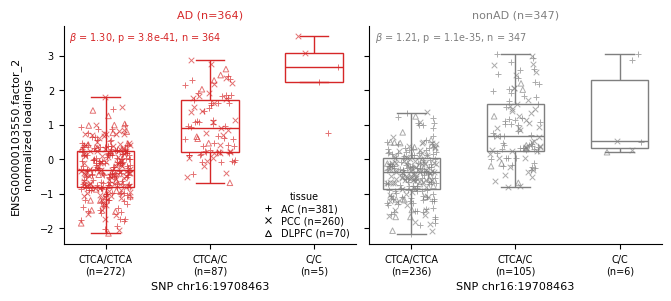

In [56]:
POOLED_ROOT = 'k3_qqnorm_by_AD'
two = EX.load_by_ad_tissues(KNOP1, KNOP1_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{KNOP1}.factor_2',
                      order=['CTCA/CTCA', 'CTCA/C', 'C/C'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': '+', 'PCC': 'x', 'DLPFC':'^'},
                      xlabel='SNP chr16:19708463')   # y label follows the tree
plt.show()

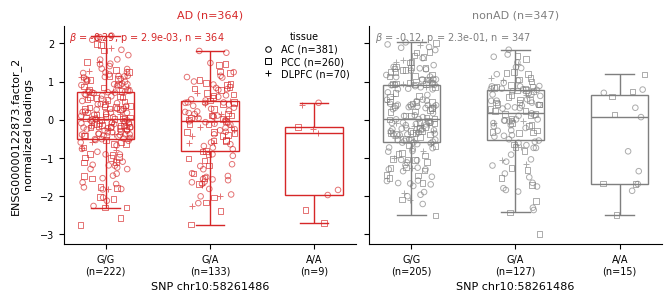

In [40]:
CISD1_SNP = 'chr10:58286894:G:A'
POOLED_ROOT = 'k3_qqnorm_by_AD'
two = EX.load_by_ad_tissues(CISD1, CISD1_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{CISD1}.factor_2',
                      order=['G/G', 'G/A', 'A/A'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's', 'DLPFC':'+'},
                      xlabel='SNP chr10:58261486')   # y label follows the tree
plt.show()

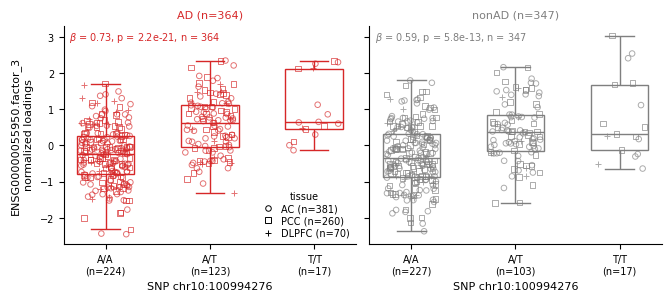

In [42]:
KNOP1 = 'ENSG00000103550'
CISD1 = 'ENSG00000122873'
MRPL43 = 'ENSG00000055950'
KLF16 = 'ENSG00000129911'
YPEL3 = 'ENSG00000090238'
TSPAN14 = 'ENSG00000108219'

MRPL43_SNP = 'chr10:100994276:A:T'
POOLED_ROOT = 'k3_qqnorm_by_AD'
two = EX.load_by_ad_tissues(MRPL43, MRPL43_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{MRPL43}.factor_3',
                      order=['A/A', 'A/T', 'T/T'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's', 'DLPFC':'+'},
                      xlabel='SNP chr10:100994276')   # y label follows the tree
plt.show()

            transcript_id           factors strand  n_exons     start       end
ENSG00000055950.isoform_1 factor_1:factor_2      -        3 100986273 100987515
ENSG00000055950.isoform_2          factor_3      -        3 100969359 100987488


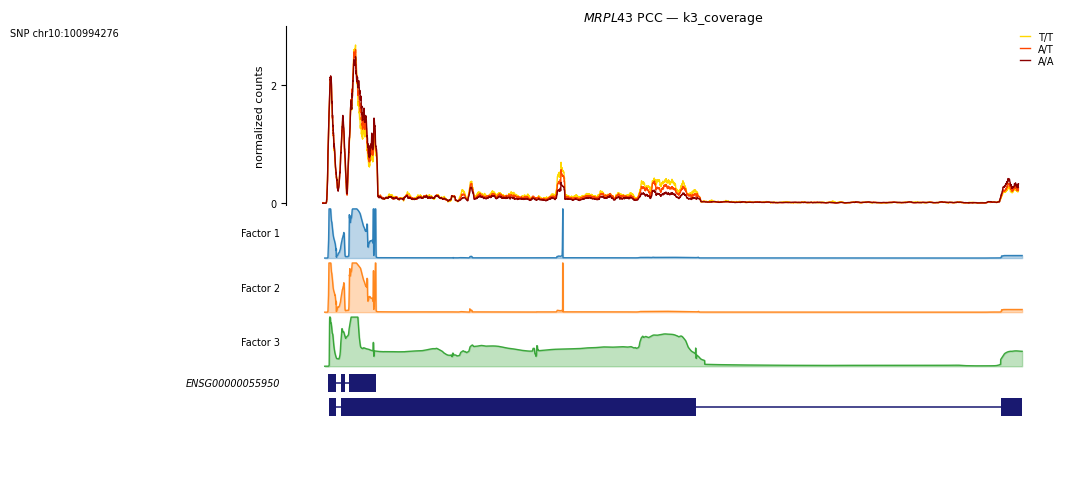

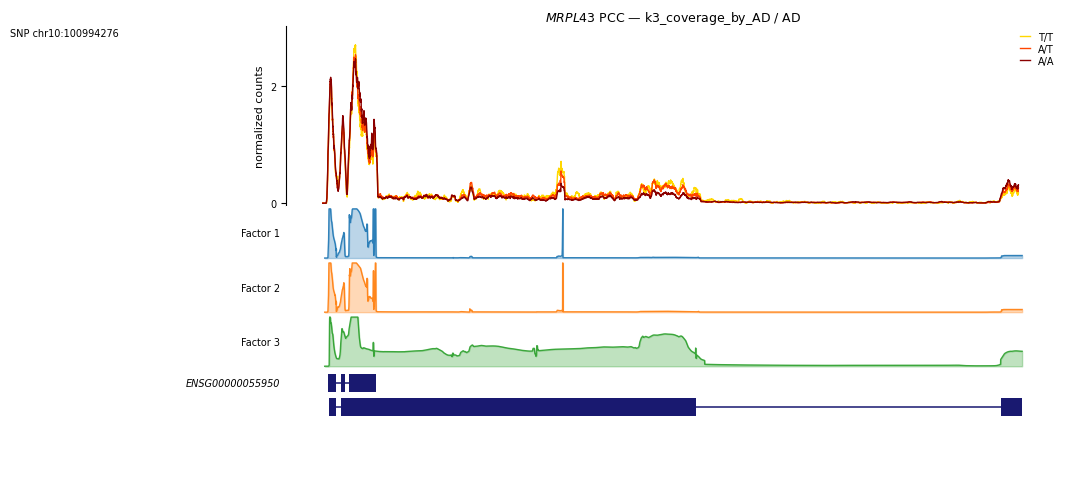

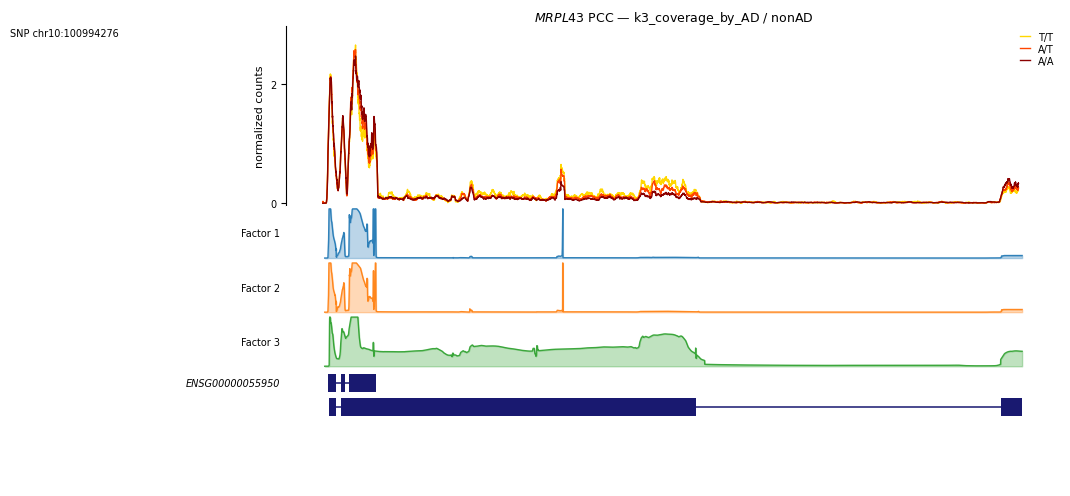

In [57]:
# The K=3 coverage trees, with the factorisation and the isoform bed switched to
# match: k=3 reads snmf_3, and H.K3_ISOFORMS is the gao_k3 bed. Mixing a K=3
# coverage with the K=5 bed gives the same xlim but shifts the exon models.
import Figure5_helpers as H

knop1_fac_k3 = EX.load_factors(MRPL43, k=3, iso_path=H.K3_ISOFORMS)
print(EX.gene_isoforms(MRPL43, iso_path=H.K3_ISOFORMS).to_string(index=False))

for root, grp in [('k3_coverage', None),
                  ('k3_coverage_by_AD', 'AD'),
                  ('k3_coverage_by_AD', 'nonAD')]:
    cov = EX.load_coverage(MRPL43, MRPL43_SNP, 'PCC', root=root, group=grp,
                           iso_path=H.K3_ISOFORMS)
    EX.plot_locus(cov, knop1_fac_k3,
                  title=f'$\\it{{MRPL43}}$ PCC — {root}' + (f' / {grp}' if grp else ''),
                  snp_label='SNP chr10:100994276', figsize=(9, 4.6))
    plt.show()

            transcript_id  factors strand  n_exons    start      end
ENSG00000108219.isoform_1 factor_1      +        8 80454167 80531446
ENSG00000108219.isoform_2 factor_2      +        9 80454229 80522977
ENSG00000108219.isoform_3 factor_3      +        6 80454256 80521924


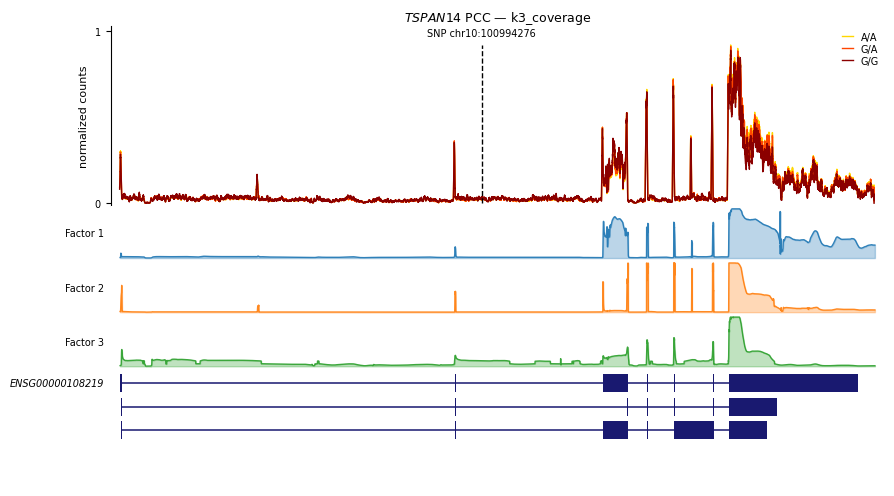

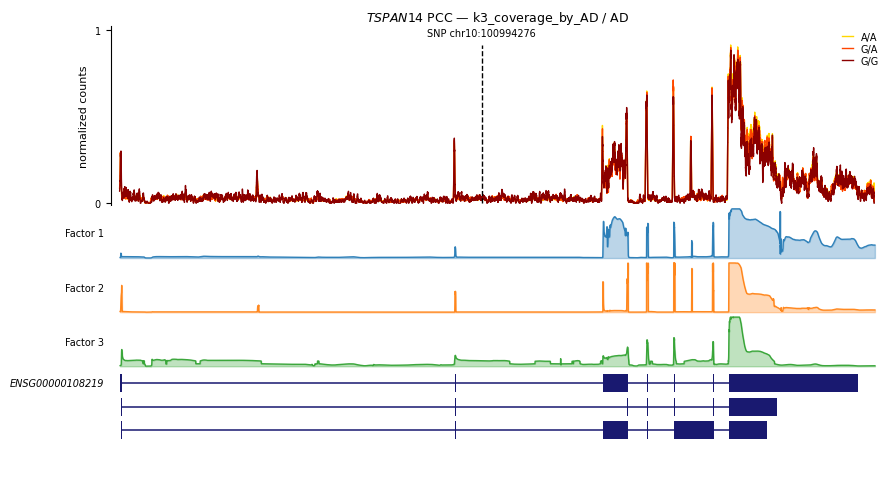

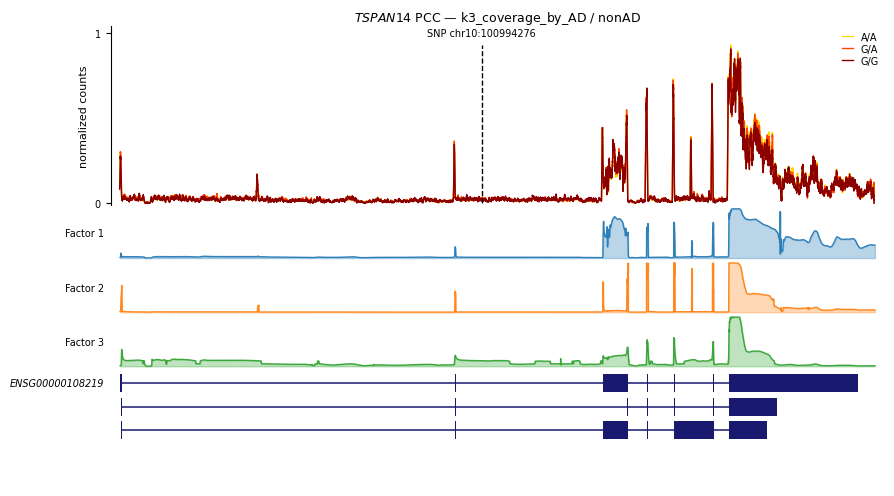

In [ ]:
# The K=3 coverage trees, with the factorisation and the isoform bed switched to
# match: k=3 reads snmf_3, and H.K3_ISOFORMS is the gao_k3 bed. Mixing a K=3
# coverage with the K=5 bed gives the same xlim but shifts the exon models.
import Figure5_helpers as H

knop1_fac_k3 = EX.load_factors(TSPAN14, k=3, iso_path=H.K3_ISOFORMS)
print(EX.gene_isoforms(TSPAN14, iso_path=H.K3_ISOFORMS).to_string(index=False))

for root, grp in [('k3_coverage', None),
                  ('k3_coverage_by_AD', 'AD'),
                  ('k3_coverage_by_AD', 'nonAD')]:
    cov = EX.load_coverage(TSPAN14, TSPAN14_SNP, 'PCC', root=root, group=grp,
                           iso_path=H.K3_ISOFORMS)
    EX.plot_locus(cov, knop1_fac_k3,
                  title=f'$\\it{{TSPAN14}}$ PCC — {root}' + (f' / {grp}' if grp else ''),
                  snp_label='SNP chr10:80492013', figsize=(9, 4.6))
    plt.show()

In [65]:
TSPAN14_SNP

'chr10:80492013:G:A'

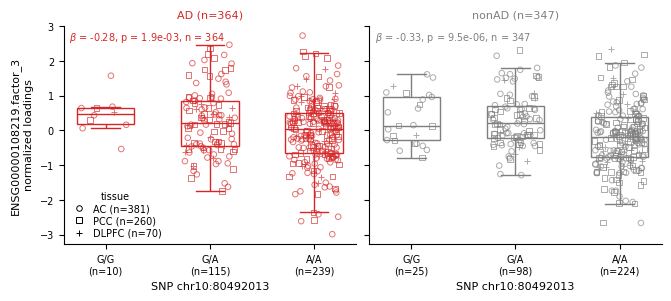

In [67]:
two = EX.load_by_ad_tissues(TSPAN14, TSPAN14_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{TSPAN14}.factor_3',
                      order=['G/G', 'G/A', 'A/A'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's', 'DLPFC':'+'},
                      xlabel='SNP chr10:80492013')   # y label follows the tree
plt.show()

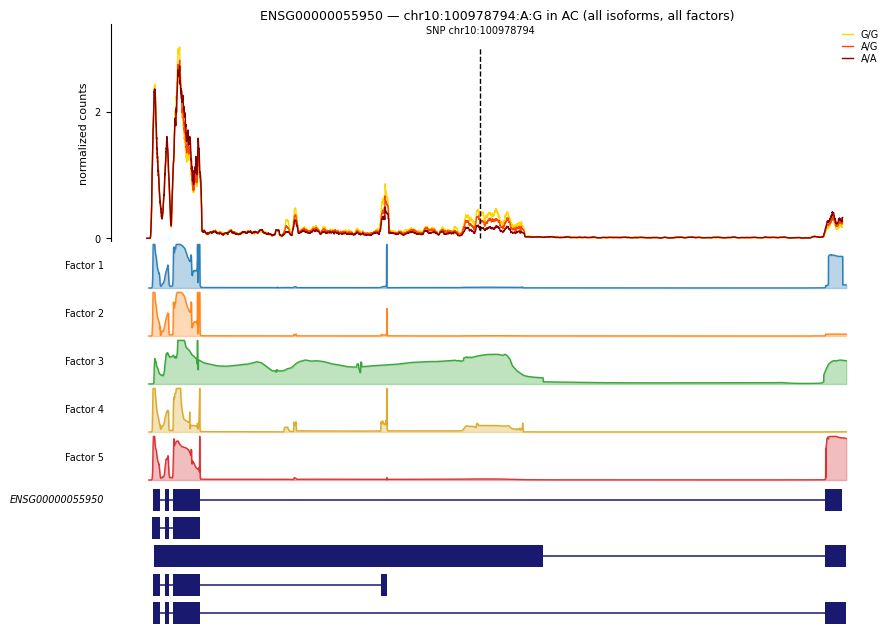

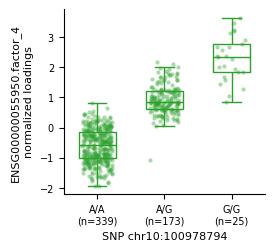

In [63]:
# A different gene-variant-tissue, with nothing else changed.
#
# With no `spec` at all, plot_locus draws every isoform of the gene under every
# factor of the model — the right starting point for a locus you have not
# looked at before. Narrow it with locus_spec() once you know which isoform and
# which factor carry the event.
MRPL43_SNP = 'chr10:100978794:A:G'
GENE, SNP, TISSUE = MRPL43, MRPL43_SNP, 'AC'

cov = EX.load_coverage(GENE, SNP, TISSUE)
fac = EX.load_factors(GENE, k=5)

EX.plot_locus(cov, fac, title=f'{GENE} — {SNP} in {TISSUE} (all isoforms, all factors)',
              snp_label=f'SNP {SNP.rsplit(":", 2)[0]}',
              figsize=(9, 6), track_h=0.22)
plt.show()

box = EX.load_boxplot(GENE, SNP, TISSUE)
EX.plot_genotype_boxplot(box, f'{GENE}.factor_4', order=['A/A', 'A/G', 'G/G'],
                         color='tab:green', xlabel=f'SNP {SNP.rsplit(":", 2)[0]}')
plt.show()

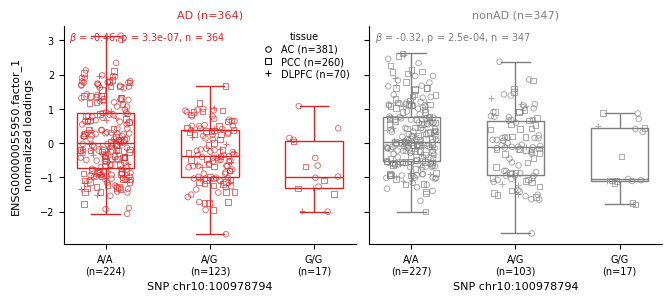

In [77]:
# YPEL3_SNP = 'chr16:30022107:A:G'
POOLED_ROOT = 'k3_qqnorm_by_AD'
two = EX.load_by_ad_tissues(MRPL43, MRPL43_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{MRPL43}.factor_1',
                      order=['A/A', 'A/G', 'G/G'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's', 'DLPFC':'+'},
                      xlabel='SNP chr10:100978794')   # y label follows the tree
plt.show()

In [75]:
MRPL43_SNP

'chr10:100978794:A:G'

In [69]:
# # A different gene-variant-tissue, with nothing else changed.
# #
# # With no `spec` at all, plot_locus draws every isoform of the gene under every
# # factor of the model — the right starting point for a locus you have not
# # looked at before. Narrow it with locus_spec() once you know which isoform and
# # which factor carry the event.
# GENE, SNP, TISSUE = TSPAN14, TSPAN14_SNP, 'AC'

# cov = EX.load_coverage(GENE, SNP, TISSUE)
# fac = EX.load_factors(GENE, k=5)

# EX.plot_locus(cov, fac, title=f'{GENE} — {SNP} in {TISSUE} (all isoforms, all factors)',
#               snp_label=f'SNP {SNP.rsplit(":", 2)[0]}',
#               figsize=(9, 6), track_h=0.22)
# plt.show()

# box = EX.load_boxplot(GENE, SNP, TISSUE)
# EX.plot_genotype_boxplot(box, f'{GENE}.factor_4', order=['G/G', 'G/A', 'A/A'],
#                          color='tab:green', xlabel=f'SNP {SNP.rsplit(":", 2)[0]}')
# plt.show()

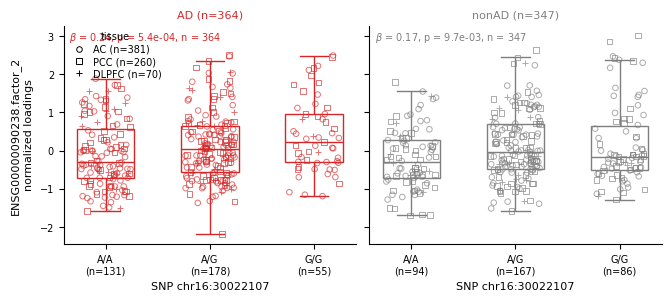

In [51]:
YPEL3_SNP = 'chr16:30022107:A:G'
POOLED_ROOT = 'k3_qqnorm_by_AD'
two = EX.load_by_ad_tissues(YPEL3, YPEL3_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{YPEL3}.factor_2',
                      order=['A/A', 'A/G', 'G/G'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's', 'DLPFC':'+'},
                      xlabel='SNP chr16:30022107')   # y label follows the tree
plt.show()

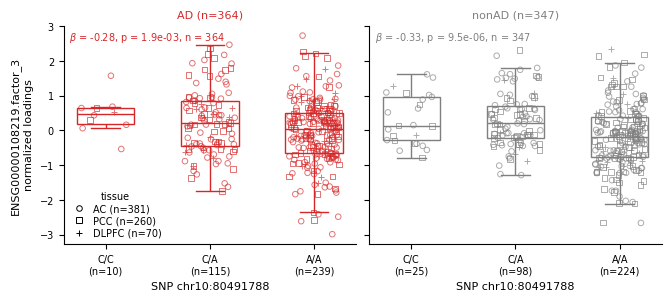

In [74]:
TSPAN14_SNP = 'chr10:80491788:C:A'
POOLED_ROOT = 'k3_qqnorm_by_AD'
two = EX.load_by_ad_tissues(TSPAN14, TSPAN14_SNP, tissues=('AC', 'PCC', 'DLPFC'),
                            root=POOLED_ROOT)
EX.plot_by_ad_boxplot(two, f'{TSPAN14}.factor_3',
                      order=['C/C', 'C/A', 'A/A'],
                      regression=True, reg_covariates=['tissue'],
                      tissue_markers={'AC': 'o', 'PCC': 's', 'DLPFC':'+'},
                      xlabel='SNP chr10:80491788')   # y label follows the tree
plt.show()

In [ ]:
CISD1_SNP
chr10:58261486:A:T

'chr10:58286894:G:A'

## The fits as numbers

`genotype_regression` fits `factor ~ dosage (+ covariates)` by OLS; the plots
annotate it, and `regression_table` tabulates it per AD group and per tissue.
Dosage is the position in `order`, so beta is per step along the order you give.

In [20]:
# The same fits as numbers rather than annotations.
#
# `regression_table` runs genotype_regression per AD group (and per tissue with
# by_tissue=True), plus a pooled 'all' row — the check that a pooled effect is
# not carried by a single tissue.
tab = EX.regression_table(knop1_pooled, f'{KNOP1}.factor_2',
                          ['CTCA/CTCA', 'CTCA/C', 'C/C'],
                          covariates=['tissue'], by_tissue=True)
print(tab.drop(columns='formula').to_string(index=False))

# Any single fit on its own, e.g. the published panel F:
res = EX.genotype_regression(knop1_box, f'{KNOP1}.factor_2',
                             ['CTCA/CTCA', 'CTCA/C', 'C/C'])
print('\npanel F:', res['formula'], '->', EX.format_regression(res))

# Dosage follows `order`, so reversing it flips the sign of beta and leaves the
# p-value alone:
rev = EX.genotype_regression(knop1_box, f'{KNOP1}.factor_2',
                             ['C/C', 'CTCA/C', 'CTCA/CTCA'])
print('reversed:', EX.format_regression(rev))

group       tissue     beta       se         pval   n       r2
   AD all (pooled) 0.156123 0.012532 7.231362e-30 364 0.335658
   AD           AC 0.142487 0.014232 2.367717e-19 200 0.336092
   AD        DLPFC 0.228494 0.075155 4.454804e-03  37 0.208921
   AD          PCC 0.161764 0.020074 5.286303e-13 127 0.341886
nonAD all (pooled) 0.143716 0.012378 1.654111e-26 347 0.285559
nonAD           AC 0.159061 0.016705 1.200115e-17 181 0.336202
nonAD        DLPFC 0.093186 0.061134 1.375718e-01  33 0.069725
nonAD          PCC 0.136319 0.017143 7.520682e-13 133 0.325541
  all all (pooled) 0.147697 0.008876 1.034554e-52 711 0.293109

panel F: ENSG00000103550.factor_2 ~ dosage -> $\beta$ = 1.21, p = 3.8e-50, n = 370
reversed: $\beta$ = -1.21, p = 3.8e-50, n = 370


In [85]:
locus_csv = pd.read_csv('../../code/k3_figure_202609-v2/locuscompare_input/ENSG00000103550.locuscompare_input.csv')

/scratch/midway3/cnajar/anaconda3/envs/leafcutter2/lib/python3.12/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


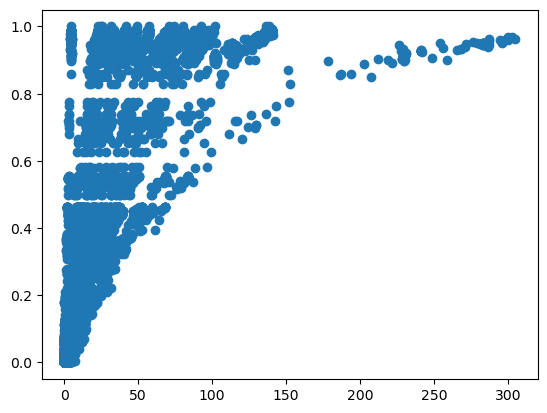

In [89]:
plt.scatter(-np.log10(locus_csv.pvalue), locus_csv.r2)

[<Axes: title={'center': 'KNOP1  (K=5)'}>,
 <Axes: >,
 <Axes: >,
 <Axes: >,
 <Axes: >]

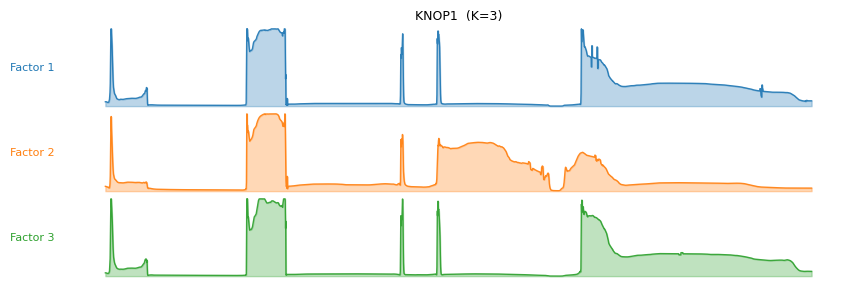

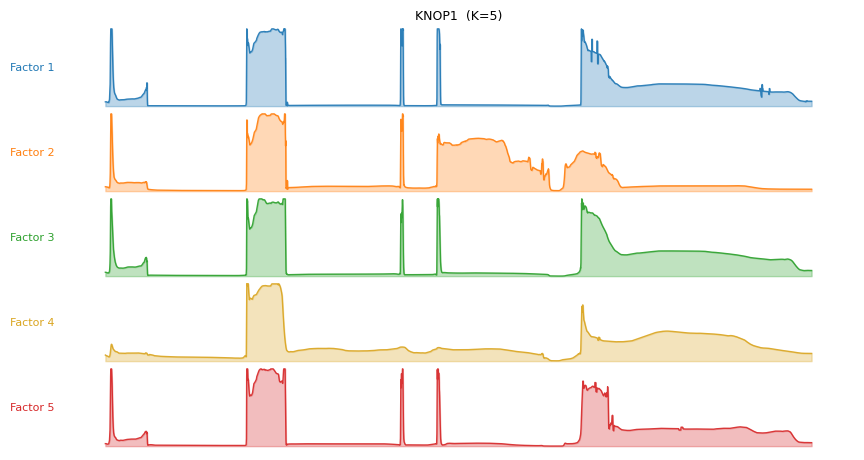

In [4]:
def plot_gene_factors(gene, k=5, factor_list=None, colors=None, figwidth=9.0,
                      track_h=0.85, lm=False, xlim=None, pad=1000, title=None,
                      fs_label=8, lw=1.0, fig=None):
    """
    The factor tracks of one gene, and nothing else — no coverage, no isoforms.

    gene         gene symbol ('KNOP1') or Ensembl id ('ENSG00000103550')
    k            3 or 5; picks snmf_3 / snmf_5 and the matching isoform bed
                 (gao_k3 for K=3, gao for K=5 — they differ, and the track
                 coordinates come from the factorisation either way)
    factor_list  which tracks, as ['factor1', 'factor2']; default all of them
    colors       one colour per track; default the tab10-ish factor palette
    lm           False keeps the raw smoothed factors. True restores the
                 detrending in Figure5_plot_helpers.factor_lm, which divides a
                 factor by a line fitted along the gene when that line's slope
                 runs with the strand.

    Returns the list of axes, one per factor.
    """
    import numpy as np
    import pandas as pd
    from matplotlib import pyplot as plt
    import Figure5_examples as EX
    import Figure5_helpers as H
    import Figure5_plot_helpers as PH

    # gene symbol -> Ensembl id, if needed
    gene_id = gene
    if not str(gene).startswith('ENSG'):
        gd = pd.read_csv(H.GENES_DIR, sep='\t', names=['gene', 'gene_id', 'loc'])
        gd['gene_id'] = gd.gene_id.apply(lambda x: x.split('.')[0])
        hit = gd.loc[gd.gene == gene]
        if hit.empty:
            raise KeyError(f'no Ensembl id for {gene!r} in {H.GENES_DIR}')
        gene_id = hit.gene_id.iloc[0]

    iso_path = H.K3_ISOFORMS if int(k) == 3 else H.GAO_ISOFORMS
    fac = EX.load_factors(gene_id, k=int(k), iso_path=iso_path)

    if factor_list is None:
        factor_list = [f'factor{i + 1}' for i in range(fac['EF_smooth'].shape[1])]
    if colors is None:
        colors = ['tab:blue', 'tab:orange', 'tab:green', 'goldenrod', 'tab:red']
    colors = list(colors)[:len(factor_list)]

    if xlim is None:
        xc = fac['xlim_coords']
        xlim = (xc[0] - pad, xc[-1] + pad)

    n = len(factor_list)
    fig = fig or plt.figure(figsize=(figwidth, track_h * n))
    axes = [fig.add_axes([0.10, 1 - (i + 1) / n, 0.88, 1 / n]) for i in range(n)]

    PH.plot_factors_wrapper(fac['EF_smooth'], fac['coords'], gene,
                            factor_list=factor_list, xlim=xlim, mute_y_axis=True,
                            ax=axes, strand=fac['strand'], colores=colors,
                            lwidth=lw, lm=lm)
    for ax, f, c in zip(axes, factor_list, colors):
        ax.set_xticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.text(-0.01, 0.5, f'Factor {f.replace("factor", "")}',
                transform=ax.transAxes, ha='right', va='center',
                fontsize=fs_label, color=c)
    axes[0].set_title(title if title is not None else f'{gene}  (K={k})',
                      fontsize=fs_label + 1, pad=4)
    return axes
# Usage:

plot_gene_factors('KNOP1', k=3)                      # 3 tracks
plot_gene_factors('KNOP1', k=5)                      # 5 tracks
# plot_gene_factors('ENSG00000122873', k=3)            # Ensembl id works too
# plot_gene_factors('KNOP1', k=5, factor_list=['factor1', 'factor2'])
# The one thing 

[<Axes: title={'center': 'ENSG00000103510  (K=3)'}>, <Axes: >, <Axes: >]

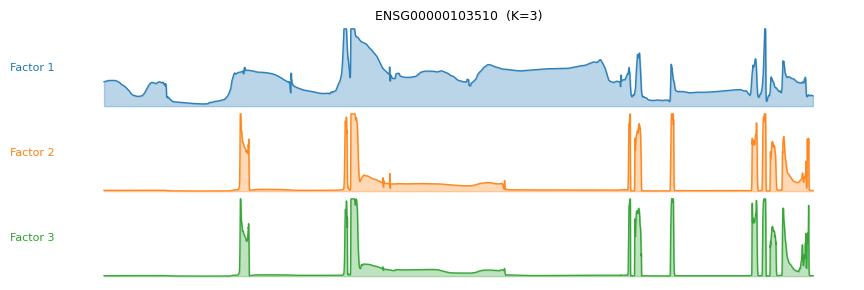

In [11]:
plot_gene_factors('ENSG00000103510', k=3)                      # 3 tracks


locus_csv

## k5_CISD1 — the marked CISD1 figure, on the K=5 trees

`code/k5_CISD1/` holds one gene and one variant on the K=5 factorisation.
Its filenames spell the variant with **underscores** (`chr10_58261486_A_T`)
where the published trees use colons, and it is a different SNP from the one
the K=3 figure uses — pass the variant exactly as the filename has it.


In [2]:
# The four k5_CISD1 trees are registered in EX.RDS_ROOTS, so nothing about the
# calls changes -- only `root` and the variant spelling.
K5_GENE, K5_SNP = EX.K5_CISD1_GENE, EX.K5_CISD1_VARIANT
K5_ORDER = ['A/A', 'A/T', 'T/T']

print(EX.compare_roots(K5_GENE, K5_SNP, 'AC', kind='boxplot',
                       roots=['k5_cisd1_qqnorm', 'k5_cisd1_qqnorm_by_AD'])[
    ['root', 'group', 'exists']].to_string(index=False))
print()
print(EX.compare_roots(K5_GENE, K5_SNP, 'AC', kind='coverage',
                       roots=['k5_cisd1_coverage', 'k5_cisd1_coverage_by_AD'])[
    ['root', 'group', 'exists']].to_string(index=False))


                 root group  exists
      k5_cisd1_qqnorm   NaN    True
k5_cisd1_qqnorm_by_AD    AD    True
k5_cisd1_qqnorm_by_AD nonAD    True

                   root group  exists
      k5_cisd1_coverage   NaN    True
k5_cisd1_coverage_by_AD    AD    True
k5_cisd1_coverage_by_AD nonAD    True


### The marked figure, replicated

Same call as the K=3 version; `root` and `order` change, and the factor is the
K=5 one (`factor_4`, the factor panel H uses) rather than K=3's `factor_2`.


          ENSG00000122873.factor_3  ENSG00000122873.factor_1  ENSG00000122873.factor_4  ENSG00000122873.factor_5  ENSG00000122873.factor_2
genotype                                                                                                                                  
A/A                         -0.018                     0.000                     0.098                    -0.063                    -0.010
A/T                         -0.073                    -0.006                    -0.116                     0.140                     0.041
T/T                         -0.241                    -0.591                    -0.409                     0.709                     0.356

group                                      model    beta     se     pval   n     r2
   AD ENSG00000122873.factor_4 ~ dosage + tissue -0.3222 0.1076 0.002933 364 0.0276
nonAD ENSG00000122873.factor_4 ~ dosage + tissue -0.1636 0.1047 0.118961 347 0.0137


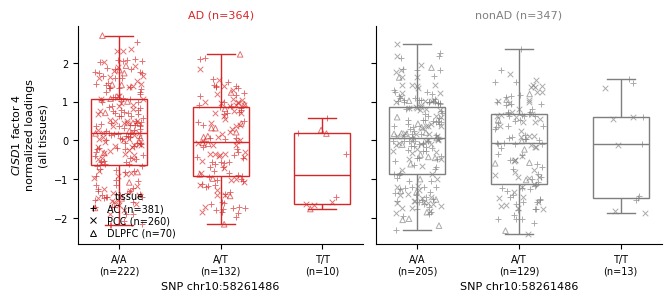

In [3]:
K5_POOLED_ROOT = 'k5_cisd1_qqnorm_by_AD'

cisd1_k5_pooled = EX.load_by_ad_tissues(K5_GENE, K5_SNP, root=K5_POOLED_ROOT)
print(cisd1_k5_pooled.groupby('genotype')[EX.factor_columns(cisd1_k5_pooled)]
      .mean().reindex(K5_ORDER).round(3).to_string())

# The fits are printed here rather than drawn on the panel: the annotation
# needs headroom above the boxes, and that compression flattens the effect.
_ax = EX.plot_by_ad_boxplot(cisd1_k5_pooled, f'{K5_GENE}.factor_4',
                            order=K5_ORDER, legend_loc='lower left',
                            regression=True, reg_covariates=['tissue'],
                            ylabel=f'$\\it{{CISD1}}$ factor 4\n'
                                   f'{EX.loading_label(K5_POOLED_ROOT)}\n(all tissues)',
                            xlabel=f'SNP {EX.snp_label(K5_SNP)}')
print()
print(EX.report_regressions(_ax).to_string(index=False))
plt.show()


### The same factor without splitting by AD

The flat `k5_cisd1_qqnorm` tree rather than the by-AD one, so all samples are
pooled across the three tissues. This is a **larger** sample than the split
above: the by-AD trees keep only samples with an AD/control label, while the
flat tree also carries the unlabelled ones.


998 samples ({'AC': 537, 'DLPFC': 91, 'PCC': 370}) vs 711 in the by-AD split
          ENSG00000122873.factor_3  ENSG00000122873.factor_1  ENSG00000122873.factor_4  ENSG00000122873.factor_5  ENSG00000122873.factor_2
genotype                                                                                                                                  
A/A                         -0.066                     0.050                     0.060                    -0.056                    -0.002
A/T                         -0.073                    -0.052                    -0.115                     0.205                     0.025
T/T                         -0.110                    -0.547                    -0.587                     0.607                     0.383

      group                                      model    beta     se     pval   n     r2
all samples ENSG00000122873.factor_4 ~ dosage + tissue -0.2297 0.0617 0.000208 998 0.0141


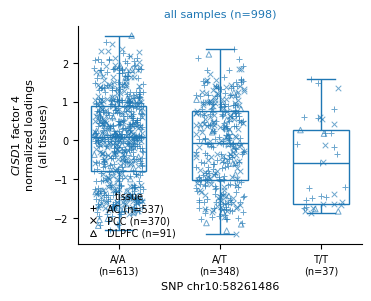

In [4]:
cisd1_k5_all = EX.load_pooled_tissues(K5_GENE, K5_SNP, root='k5_cisd1_qqnorm')
print(f'{len(cisd1_k5_all)} samples '
      f'({cisd1_k5_all.groupby("tissue").size().to_dict()}) '
      f'vs {len(cisd1_k5_pooled)} in the by-AD split')
print(cisd1_k5_all.groupby('genotype')[EX.factor_columns(cisd1_k5_all)]
      .mean().reindex(K5_ORDER).round(3).to_string())

_ax = EX.plot_by_ad_boxplot(cisd1_k5_all, f'{K5_GENE}.factor_4',
                            order=K5_ORDER, groups=('all samples',),
                            figsize=(3.6, 2.9), legend_loc='lower left',
                            regression=True, reg_covariates=['tissue'],
                            ylabel=f'$\\it{{CISD1}}$ factor 4\n'
                                   f'{EX.loading_label("k5_cisd1_qqnorm")}\n(all tissues)',
                            xlabel=f'SNP {EX.snp_label(K5_SNP)}')
print()
print(EX.report_regressions(_ax).to_string(index=False))
plt.show()


### Coverage and factor tracks

The K=5 factorisation and the gao isoform bed are the ones already in use, so
`load_factors(gene, k=5)` needs no extra argument; only the coverage tree is new.


            transcript_id           factors strand  n_exons    start      end
ENSG00000122873.isoform_1          factor_1      +        3 58269129 58288521
ENSG00000122873.isoform_2 factor_2:factor_4      +        3 58269126 58289682
ENSG00000122873.isoform_3          factor_3      +        2 58269063 58288245
ENSG00000122873.isoform_4          factor_5      +        3 58269129 58287757


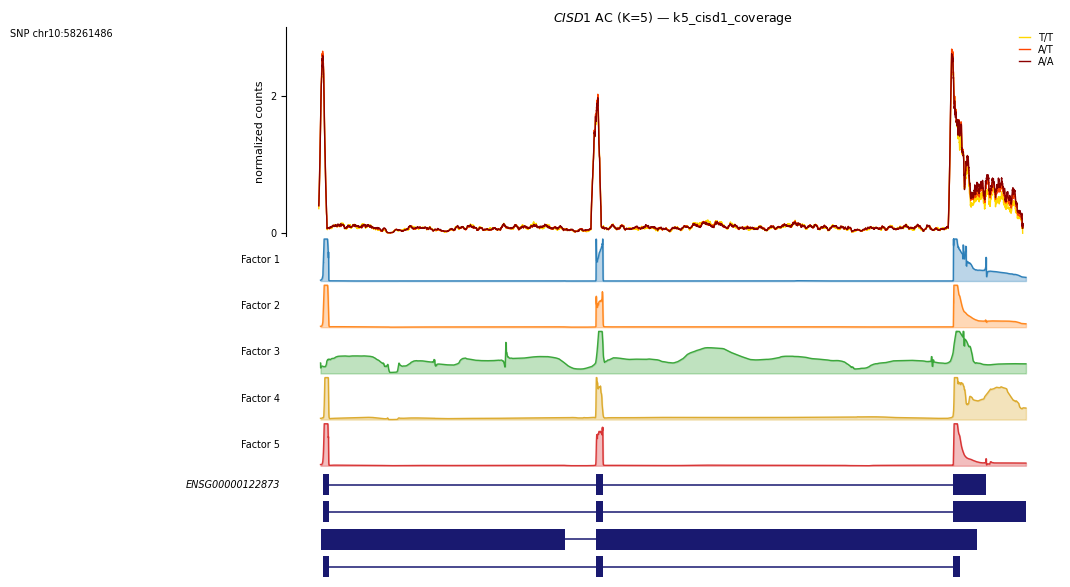

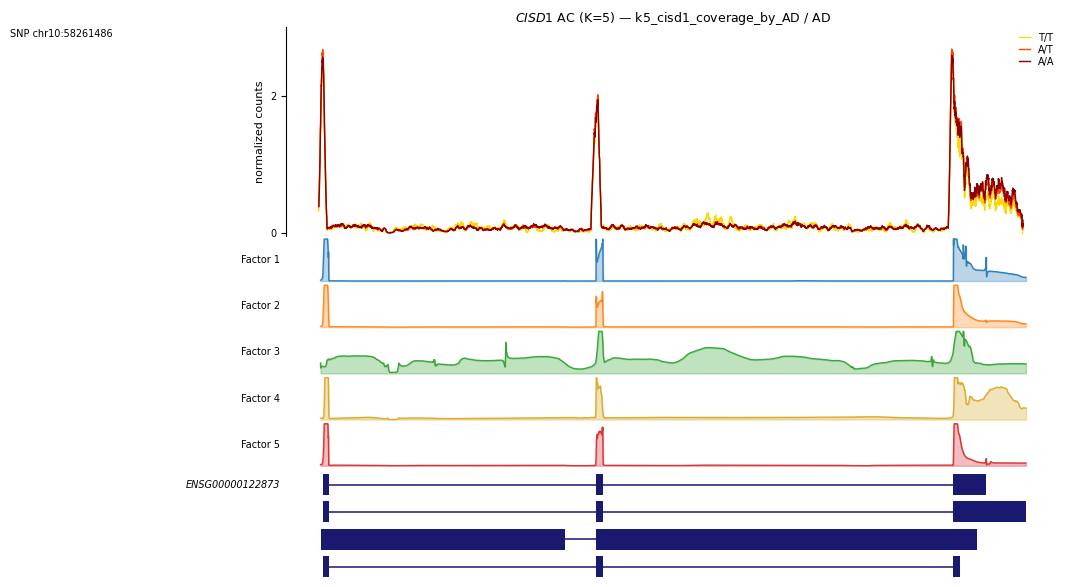

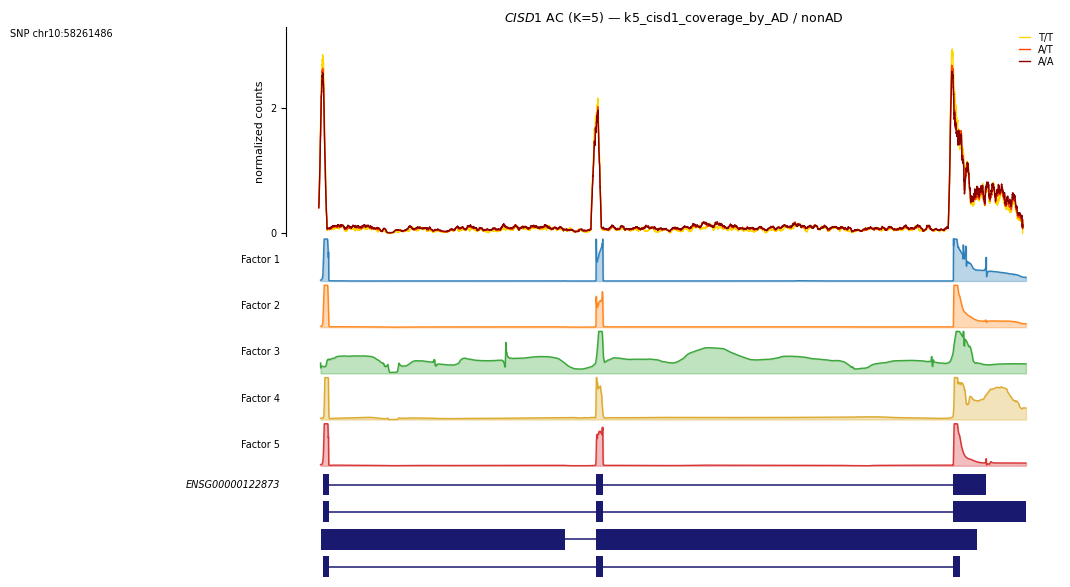

In [5]:
cisd1_k5_fac = EX.load_factors(K5_GENE, k=5)          # gao bed, 5 factors
print(EX.gene_isoforms(K5_GENE).to_string(index=False))

for root, grp in [('k5_cisd1_coverage', None),
                  ('k5_cisd1_coverage_by_AD', 'AD'),
                  ('k5_cisd1_coverage_by_AD', 'nonAD')]:
    cov = EX.load_coverage(K5_GENE, K5_SNP, 'AC', root=root, group=grp)
    EX.plot_locus(cov, cisd1_k5_fac,
                  title=f'$\\it{{CISD1}}$ AC (K=5) — {root}'
                        + (f' / {grp}' if grp else ''),
                  snp_label=f'SNP {EX.snp_label(K5_SNP)}',
                  figsize=(9, 5.5), track_h=0.22)
    plt.show()
